# Project 2 — Text-to-Image Generation
## Milestone 2: Integration & Training (Text-Conditional DDPM)

**IE 7615** — Project 2, Milestone 2

**David Fung**

This notebook integrates the CLIP text encoder (Milestone 1) with a from-scratch
denoising diffusion probabilistic model (DDPM) as the conditioning signal. We train a
text-conditional U-Net on the curated Flickr30k subset at 64x64 resolution so that
training fits within a modest compute budget. Classifier-free guidance (CFG) is enabled
by learning a null text token and dropping the caption embedding with a fixed probability
during training. This notebook builds directly on the dataset and CLIP pipeline from
Milestone 1 — it does not rebuild them.


In [1]:
import os
import time
import json
import math
import random
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from transformers import CLIPProcessor, CLIPModel

print(f"PyTorch:    {torch.__version__}")
print(f"CUDA:       {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU:        {torch.cuda.get_device_name(0)}")


PyTorch:    2.12.0+cu130
CUDA:       True
GPU:        NVIDIA GB10


In [2]:
# PROJECT CONSTANTS

GLOBAL_SEED = 42
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)
torch.manual_seed(GLOBAL_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(GLOBAL_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# SMOKE_TEST = True for a fast end-to-end sanity run (fewer epochs, smaller batch).
SMOKE_TEST = False

# Paths (relative to this notebook, Milestone_2/)
DATA_DIR      = "../data"
CURATED_DIR   = os.path.join(DATA_DIR, "curated")
MANIFEST_PATH = os.path.join(CURATED_DIR, "manifest.csv")
OUTPUT_DIR    = "outputs"
GALLERY_DIR   = "gallery"
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(GALLERY_DIR, exist_ok=True)

# Models
CLIP_MODEL_NAME = "openai/clip-vit-base-patch32"
CLIP_TEXT_DIM   = 512                 # CLIP ViT-B/32 hidden size

#CLIP_MODEL_NAME = "openai/clip-vit-large-patch14"
#CLIP_TEXT_DIM   = 768

# DDPM configuration
IMG_SIZE       = 256
IN_CHANNELS    = 3
BASE_CHANNELS  = 96                   # U-Net base width (64/128/256/512)
COND_DIM       = 256                  # conditioning vector dim (time + text)
N_TIMESTEPS    = 1000                 # diffusion length T
BETA_SCHEDULE  = "cosine"             # "linear" or "cosine"

# Training hyperparameters
BATCH_SIZE        = 32
EPOCHS            = 60 if not SMOKE_TEST else 30
LEARNING_RATE     = 1e-4
WEIGHT_DECAY      = 1e-2
TEXT_DROPOUT_PROB = 0.15              # CFG: replace caption embedding with null w.p. this
EMA_DECAY         = 0.999
GRAD_CLIP         = 1.0
VAL_FRACTION      = 0.10              # held-out validation fraction
SAMPLE_EVERY      = 1                 # generate a validation grid every N epochs

print(f"Device:             {DEVICE}")
print(f"Smoke test:         {SMOKE_TEST}")
print(f"Image size:         {IMG_SIZE}x{IMG_SIZE}")
print(f"Beta schedule:      {BETA_SCHEDULE}")
print(f"Batch size / Epochs:{BATCH_SIZE} / {EPOCHS}")
print(f"Text dropout (CFG): {TEXT_DROPOUT_PROB}")


Device:             cuda
Smoke test:         False
Image size:         256x256
Beta schedule:      cosine
Batch size / Epochs:32 / 60
Text dropout (CFG): 0.15


## Task 1 — Data Preparation & Text Embeddings

Read the image–caption manifest produced by Milestone 1, split it into train/val,
precompute and cache the frozen CLIP text embeddings once, and build a PyTorch dataset
that yields (32x32 image, 512-dim text embedding) pairs.


In [3]:
def clean_caption(text):
    """Light, whitespace-safe normalisation before CLIP encoding."""
    text = str(text).strip().lower()
    return ' '.join(text.split())          # collapses newlines / repeated spaces

def load_manifest(path):
    df = pd.read_csv(path)
    df = df.drop_duplicates(subset=['image_id']).reset_index(drop=True)
    return df

df_manifest = load_manifest(MANIFEST_PATH)
df_manifest['caption'] = df_manifest['caption'].apply(clean_caption)
print(f"Loaded {len(df_manifest)} curated pairs from {MANIFEST_PATH}")
print(f"Caption length (words): min={df_manifest['caption'].str.split().str.len().min()}, "
      f"max={df_manifest['caption'].str.split().str.len().max()}")
print(df_manifest.head())

# Deterministic train/val split (last VAL_FRACTION of rows -> val)
split    = int(round(len(df_manifest) * (1 - VAL_FRACTION)))
df_train = df_manifest.iloc[:split].reset_index(drop=True)
df_val   = df_manifest.iloc[split:].reset_index(drop=True)
print(f"\nTrain: {len(df_train)}   Val: {len(df_val)}")


Loaded 5000 curated pairs from ../data/curated/manifest.csv
Caption length (words): min=8, max=78
   image_id                                            caption
0         0  two young guys with shaggy hair look at their ...
1         1  several men in hard hats are operating a giant...
2         2  a child in a pink dress is climbing up a set o...
3         3  someone in a blue shirt and hat is standing on...
4         4  two men, one in a gray shirt, one in a black s...

Train: 4500   Val: 500


In [4]:
import os, glob
for f in glob.glob(os.path.join(OUTPUT_DIR, "clip_text_embeddings_*.npy")):
    os.remove(f)
    print(f"Deleted {f}")

Deleted outputs/clip_text_embeddings_train.npy
Deleted outputs/clip_text_embeddings_val.npy


In [5]:
clip_model     = CLIPModel.from_pretrained(CLIP_MODEL_NAME).to(DEVICE)
clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL_NAME)
clip_model.eval()
for p in clip_model.parameters():
    p.requires_grad_(False)

def encode_captions(texts, batch_size=64):
    embs = []
    for i in range(0, len(texts), batch_size):
        # ADD truncation=True and max_length=77 here
        inputs = clip_processor(
            text=texts[i:i+batch_size], 
            return_tensors="pt",
            padding=True, 
            truncation=True,      # <--- Fix 1: Enable truncation
            max_length=77         # <--- Fix 2: Match CLIP's limit
        ).to(DEVICE)
        
        with torch.no_grad():
            out = clip_model.get_text_features(**inputs)
            
            if out.dim() == 3:          # (B, 77, 512) — full sequence
                out = out[:, 0, :]      # CLS token → (B, 512)
            out = torch.nn.functional.normalize(out, dim=-1)
            
        embs.append(out.cpu().numpy())
    return np.concatenate(embs, axis=0).astype(np.float32)

emb_train_path = os.path.join(OUTPUT_DIR, "clip_text_embeddings_train.npy")
emb_val_path   = os.path.join(OUTPUT_DIR, "clip_text_embeddings_val.npy")

if os.path.exists(emb_train_path) and os.path.exists(emb_val_path):
    train_emb = np.load(emb_train_path)
    val_emb   = np.load(emb_val_path)
    print("Loaded cached CLIP text embeddings.")
else:
    print("Computing CLIP text embeddings...")
    train_emb = encode_captions(df_train['caption'].tolist())
    val_emb   = encode_captions(df_val['caption'].tolist())
    np.save(emb_train_path, train_emb)
    np.save(emb_val_path, val_emb)
    print(f"Saved {train_emb.shape[0]} train + {val_emb.shape[0]} val embeddings.")

print(f"Train embeddings: {train_emb.shape}, dtype={train_emb.dtype}, "
      f"norm={np.linalg.norm(train_emb, axis=1).mean():.3f}")
print(f"Val embeddings:   {val_emb.shape}, dtype={val_emb.dtype}, "
      f"norm={np.linalg.norm(val_emb, axis=1).mean():.3f}")

del clip_model, clip_processor
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Computing CLIP text embeddings...
Saved 4500 train + 500 val embeddings.
Train embeddings: (4500, 512), dtype=float32, norm=1.000
Val embeddings:   (500, 512), dtype=float32, norm=1.000


In [6]:
class CuratedTextImageDataset(Dataset):
    """Yields (32x32 image in [-1,1], 512-dim CLIP text embedding)."""
    def __init__(self, image_ids, text_embeddings, img_dir, img_size, augment=False):
        self.image_ids = image_ids
        self.text_embeddings = np.asarray(text_embeddings, dtype=np.float32)
        self.img_dir = img_dir
        self.img_size = img_size
        self.augment = augment

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        img = Image.open(os.path.join(self.img_dir, str(self.image_ids[idx]))).convert("RGB")
        img = img.resize((self.img_size, self.img_size), Image.BILINEAR)
        if self.augment and random.random() > 0.5:
            img = img.transpose(Image.FLIP_LEFT_RIGHT)
        x = np.asarray(img, dtype=np.float32) / 255.0
        x = (x - 0.5) / 0.5                       # -> [-1, 1]
        x = torch.from_numpy(x).permute(2, 0, 1)
        t = torch.from_numpy(self.text_embeddings[idx])
        return x, t

def make_loader(df, embeddings, augment):
    ds = CuratedTextImageDataset(df['image_id'].tolist(), embeddings, CURATED_DIR, IMG_SIZE, augment)
    g = torch.Generator(); g.manual_seed(GLOBAL_SEED)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=augment, num_workers=0,
                      drop_last=augment, generator=g, pin_memory=torch.cuda.is_available())

train_loader = make_loader(df_train, train_emb, augment=True)
val_loader   = make_loader(df_val,   val_emb,   augment=False)

x0, t0 = next(iter(train_loader))
print(f"Sample batch: image {tuple(x0.shape)}, text {tuple(t0.shape)}")
print(f"Image range:  [{x0.min():.3f}, {x0.max():.3f}]")
print(f"Text L2 norm: {t0.norm(dim=1).mean().item():.3f}")


Sample batch: image (32, 3, 256, 256), text (32, 512)
Image range:  [-1.000, 1.000]
Text L2 norm: 1.000


## Task 2 — Text-Conditional DDPM (architecture + diffusion process)

Build a U-Net noise-prediction network conditioned on the timestep and the CLIP text
embedding via adaptive group normalisation (AdaGN). We use a cosine noise schedule and
enable classifier-free guidance by learning a **null text token**: during training the
caption embedding is replaced by this token with probability `TEXT_DROPOUT_PROB`, so at
inference we can steer the denoising with `eps = eps_uncond + s * (eps_cond - eps_uncond)`.


In [7]:
def cosine_beta_schedule(T, s=0.008):
    steps = T + 1
    t = torch.linspace(0, 1, steps, dtype=torch.float64)
    alphas_cumprod = torch.cos((t + s) / (1 + s) * math.pi * 0.5) ** 2
    betas = 1 - (alphas_cumprod[1:] / alphas_cumprod[:-1])
    return torch.clip(betas, 0.0001, 0.9999).float()

def linear_beta_schedule(T):
    return torch.linspace(0.0001, 0.02, T).float()

class GaussianDiffusion:
    """Epsilon-prediction DDPM with cosine/linear beta schedules and DDIM sampling."""
    def __init__(self, T, schedule="cosine", device="cpu"):
        self.T = T
        self.device = device
        self.betas = (cosine_beta_schedule(T) if schedule == "cosine"
                      else linear_beta_schedule(T)).to(device)
        self.alphas = 1.0 - self.betas
        self.alphas_cumprod = torch.cumprod(self.alphas, dim=0)
        self.alphas_cumprod_prev = F.pad(self.alphas_cumprod[:-1], (1, 0))
        self.sqrt_alphas_cumprod = self.alphas_cumprod.sqrt()
        self.sqrt_one_minus_alphas_cumprod = (1.0 - self.alphas_cumprod).sqrt()
        self.sqrt_recip_alphas = self.alphas.reciprocal().sqrt()
        # Official DDPM posterior coefficients
        self.posterior_mean_coef1 = self.betas * (1.0 - self.alphas_cumprod_prev) / (1.0 - self.alphas_cumprod)
        self.posterior_mean_coef2 = self.alphas * (1.0 - self.alphas_cumprod_prev) / (1.0 - self.alphas_cumprod)
        self.posterior_var = self.betas * (1.0 - self.alphas_cumprod_prev) / (1.0 - self.alphas_cumprod)

    def q_sample(self, x0, t, noise):
        a = self.sqrt_alphas_cumprod[t][:, None, None, None]
        s = self.sqrt_one_minus_alphas_cumprod[t][:, None, None, None]
        return a * x0 + s * noise

    def loss(self, model, x0, text_emb, text_dropout_prob):
        """CFG-aware diffusion loss: drop the caption embedding for a random subset."""
        B = x0.shape[0]
        t = torch.randint(0, self.T, (B,), device=x0.device)
        noise = torch.randn_like(x0)
        xt = self.q_sample(x0, t, noise)
        use_null = (torch.rand(B, device=x0.device) < text_dropout_prob).float()
        cond_emb = text_emb * (1.0 - use_null[:, None]) + model.null_text * use_null[:, None]
        eps_pred = model(xt, t, cond_emb)
        return F.mse_loss(eps_pred, noise)

    def ddim_prev(self, xt, t, eps, a_prev, eta=0.0):
        """One DDIM reverse step (deterministic when eta=0)."""
        a_t = self.alphas_cumprod[t]
        x0_pred = (xt - self.sqrt_one_minus_alphas_cumprod[t] * eps) / self.sqrt_alphas_cumprod[t]
        x0_pred = torch.clamp(x0_pred, -1.0, 1.0)
        sigma = eta * ((1.0 - a_prev) / (1.0 - a_t)).sqrt() * (1.0 - a_t / a_prev).sqrt()
        dir_xt = (1.0 - a_prev - sigma ** 2).clamp(min=0.0).sqrt() * eps
        x_prev = a_prev.sqrt() * x0_pred + dir_xt
        if eta > 0:
            x_prev = x_prev + sigma * torch.randn_like(xt)
        return x_prev

    def sample(self, model, text_emb, null_emb, guidance_scale, n_steps, seed=42, eta=0.0,
               device="cpu", img_size=32, channels=3):
        """CFG + DDIM sampling of one image (batch=1)."""
        model.eval()
        if text_emb.dim() == 1:
            text_emb = text_emb.unsqueeze(0)
        if null_emb.dim() == 1:
            null_emb = null_emb.unsqueeze(0)
        gen = torch.Generator().manual_seed(seed)
        step = max(1, self.T // n_steps)
        timesteps = list(range(self.T - step, -1, -step))
        x = torch.randn(1, channels, img_size, img_size, generator=gen).to(device)
        with torch.no_grad():
            for i, t in enumerate(timesteps):
                t_batch = torch.tensor([t], device=device)
                eps_cond   = model(x, t_batch, text_emb)
                eps_uncond = model(x, t_batch, null_emb)
                eps = eps_uncond + guidance_scale * (eps_cond - eps_uncond)
                t_prev = timesteps[i + 1] if (i + 1) < len(timesteps) else 0
                a_prev = self.alphas_cumprod[t_prev]
                x = self.ddim_prev(x, t, eps, a_prev, eta)
        x = torch.clamp(x, -1.0, 1.0)
        return x


In [8]:
def sinusoidal_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device).float() / half)
    args = t[:, None].float() * freqs[None, :]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)

class TimestepEmbed(nn.Module):
    def __init__(self, sin_dim=256, cond_dim=256):
        super().__init__()
        self.sin_dim = sin_dim
        self.mlp = nn.Sequential(nn.Linear(sin_dim, sin_dim * 4), nn.GELU(),
                                 nn.Linear(sin_dim * 4, cond_dim))
    def forward(self, t):
        return self.mlp(sinusoidal_embedding(t, self.sin_dim))

class AdaGNBlock(nn.Module):
    """Residual block whose GroupNorms are modulated by the conditioning vector."""
    def __init__(self, in_c, out_c, cond_dim, groups=8):
        super().__init__()
        self.norm1 = nn.GroupNorm(groups, in_c)
        self.conv1 = nn.Conv2d(in_c, out_c, 3, padding=1)
        self.norm2 = nn.GroupNorm(groups, out_c)
        self.conv2 = nn.Conv2d(out_c, out_c, 3, padding=1)
        self.adapt1 = nn.Sequential(nn.SiLU(), nn.Linear(cond_dim, 2 * in_c))
        self.adapt2 = nn.Sequential(nn.SiLU(), nn.Linear(cond_dim, 2 * out_c))
        self.skip = nn.Conv2d(in_c, out_c, 1) if in_c != out_c else nn.Identity()
    def _modulate(self, x, norm, adapt, cond):
        gamma, beta = adapt(cond).chunk(2, dim=-1)
        return gamma[..., None, None] * norm(x) + beta[..., None, None]
    def forward(self, x, cond):
        h = F.silu(self._modulate(x, self.norm1, self.adapt1, cond))
        h = self.conv1(h)
        h = F.silu(self._modulate(h, self.norm2, self.adapt2, cond))
        h = self.conv2(h)
        return h + self.skip(x)

class DownBlock(nn.Module):
    def __init__(self, in_c, out_c, cond_dim):
        super().__init__()
        self.res1 = AdaGNBlock(in_c, out_c, cond_dim)
        self.res2 = AdaGNBlock(out_c, out_c, cond_dim)
        self.down = nn.Conv2d(out_c, out_c, 3, stride=2, padding=1)
    def forward(self, x, cond):
        h = self.res1(x, cond)
        h = self.res2(h, cond)
        return self.down(h)

class UpBlock(nn.Module):
    def __init__(self, in_c, skip_c, out_c, cond_dim):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2)
        self.res1 = AdaGNBlock(in_c + skip_c, out_c, cond_dim)
        self.res2 = AdaGNBlock(out_c, out_c, cond_dim)
    def forward(self, x, skip, cond):
        h = torch.cat([self.up(x), skip], dim=1)
        return self.res2(self.res1(h, cond), cond)

# Added for self attention
class SelfAttention(nn.Module):
    def __init__(self, channels, heads=4):
        super().__init__()
        self.scale = (channels // heads) ** -0.5
        self.to_qkv = nn.Conv2d(channels, channels * 3, 1)
        self.to_out = nn.Conv2d(channels, channels, 1)

    def forward(self, x):
        B, C, H, W = x.shape
        qkv = self.to_qkv(x).chunk(3, dim=1)
        q, k, v = [t.reshape(B, C // 4, 4, H * W).permute(0, 2, 3, 1) for t in qkv]
        out = F.scaled_dot_product_attention(q, k, v)
        out = out.permute(0, 3, 1, 2).reshape(B, C, H, W)
        return self.to_out(out)

class TextConditionedUNet(nn.Module):
    """U-Net noise predictor conditioned on (timestep, CLIP text embedding) via AdaGN."""
    def __init__(self, in_channels=3, base=64, cond_dim=256, text_dim=512):
        super().__init__()
        self.time_embed = TimestepEmbed(256, cond_dim)
        self.text_embed = nn.Sequential(nn.Linear(text_dim, cond_dim), nn.GELU())
        self.null_text  = nn.Parameter(torch.randn(text_dim) * 0.02)   # learnable CFG null
        c = [base, base * 2, base * 4, base * 8]
        self.input_conv = nn.Conv2d(in_channels, base, 3, padding=1)
        self.downs = nn.ModuleList([DownBlock(c[i], c[i + 1], cond_dim) for i in range(3)])
        self.mid1 = AdaGNBlock(c[3], c[3], cond_dim)
        self.mid_attn = SelfAttention(c[3], heads=4)
        self.mid2 = AdaGNBlock(c[3], c[3], cond_dim)
        self.ups = nn.ModuleList([UpBlock(c[i + 1], c[i + 1], c[i], cond_dim)
                                  for i in range(2, -1, -1)])
        self.out_norm = nn.GroupNorm(8, base)
        self.out_conv = nn.Conv2d(base, in_channels, 3, padding=1)
    def forward(self, x, t, text_emb):
        cond = self.time_embed(t) + self.text_embed(text_emb)
        h = self.input_conv(x)
        skips = [h]
        for d in self.downs:
            h_res = d.res1(h, cond)
            h_res = d.res2(h_res, cond)
            skips.append(h_res) # was h and not h_res
            h = d.down(h_res) # Just added
        h = F.silu(self.mid1(h, cond))
        h = h + self.mid_attn(h) # Added for self attention
        h = self.mid2(h, cond)
        for u in self.ups:
            h = u(h, skips.pop(), cond)
        h = F.silu(self.out_norm(h))
        return self.out_conv(h)

model = TextConditionedUNet(IN_CHANNELS, BASE_CHANNELS, COND_DIM, CLIP_TEXT_DIM)
n_params = sum(p.numel() for p in model.parameters())
print(f"Model: TextConditionedUNet — {n_params/1e6:.2f}M parameters")
print(model)


Model: TextConditionedUNet — 75.42M parameters
TextConditionedUNet(
  (time_embed): TimestepEmbed(
    (mlp): Sequential(
      (0): Linear(in_features=256, out_features=1024, bias=True)
      (1): GELU(approximate='none')
      (2): Linear(in_features=1024, out_features=256, bias=True)
    )
  )
  (text_embed): Sequential(
    (0): Linear(in_features=512, out_features=256, bias=True)
    (1): GELU(approximate='none')
  )
  (input_conv): Conv2d(3, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (downs): ModuleList(
    (0): DownBlock(
      (res1): AdaGNBlock(
        (norm1): GroupNorm(8, 96, eps=1e-05, affine=True, bias=True)
        (conv1): Conv2d(96, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (norm2): GroupNorm(8, 192, eps=1e-05, affine=True, bias=True)
        (conv2): Conv2d(192, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (adapt1): Sequential(
          (0): SiLU()
          (1): Linear(in_features=256, out_features=192, bias=Tr

## Task 3 — Training

Train the text-conditional U-Net with the CFG-aware diffusion loss. We track train/val
loss, learning rate, epoch time and (on GPU) peak memory, keep an EMA of the weights,
periodically sample a fixed validation grid to visualise progress, and finally save the
checkpoint (model + EMA + config + history) for the conditional-generation notebook.


In [9]:
model = model.to(DEVICE)
ema = copy.deepcopy(model)
for p in ema.parameters():
    p.requires_grad_(False)
ema.eval()

diffusion = GaussianDiffusion(N_TIMESTEPS, BETA_SCHEDULE, DEVICE)

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

# --- Scheduler: always plan for 500 epochs, regardless of EPOCHS ---
PLANNED_EPOCHS = 500
steps_per_epoch = len(df_train) // BATCH_SIZE
warmup_steps    = min(2000, 2 * steps_per_epoch)          # cap warmup at 2 epochs
total_steps     = PLANNED_EPOCHS * steps_per_epoch         # always 500 × steps

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lambda step:
    min(1.0, step / warmup_steps) *
    0.5 * (1 + math.cos(math.pi * max(0, step - warmup_steps) / max(1, total_steps - warmup_steps)))
)

def copy_ema(src, dst, decay=EMA_DECAY):
    for p, sp in zip(dst.parameters(), src.parameters()):
        p.data.copy_(p.data * decay + sp.data * (1.0 - decay))

def tensor_to_pil(x):
    x = (x + 1) / 2
    x = x.clamp(0, 1).squeeze(0).permute(1, 2, 0).cpu().numpy()
    return Image.fromarray((x * 255).astype('uint8'))

# Fixed validation prompts to visualise progress (first 4 val rows)
VAL_PROBE_IDX = list(range(min(4, len(df_val))))
val_probe_ids   = [df_val.iloc[i]['image_id'] for i in VAL_PROBE_IDX]
val_probe_emb   = val_emb[VAL_PROBE_IDX]
val_probe_gt    = [Image.open(os.path.join(CURATED_DIR, str(i))).convert("RGB") for i in val_probe_ids]
val_probe_caption = [df_val.iloc[i]['caption'] for i in VAL_PROBE_IDX]

def generate_grid(ema_model, tag):
    """Generate 4 val prompts (guidance=7.5, 50 steps) and save a GT-vs-generated grid."""
    imgs = []
    for i in VAL_PROBE_IDX:
        emb = torch.from_numpy(val_emb[i]).to(DEVICE)
        out = diffusion.sample(ema_model, emb, ema_model.null_text,
                               guidance_scale=7.5, n_steps=50, seed=GLOBAL_SEED,
                               device=DEVICE, img_size=IMG_SIZE, channels=IN_CHANNELS)
        imgs.append(tensor_to_pil(out))
    fig, axes = plt.subplots(2, len(imgs), figsize=(2.2 * len(imgs), 4.4))
    for j, (gt, gen) in enumerate(zip(val_probe_gt, imgs)):
        axes[0, j].imshow(gt); axes[0, j].axis('off')
        axes[1, j].imshow(gen); axes[1, j].axis('off')
    axes[0, 0].set_title("Ground truth", loc='left'); axes[1, 0].set_title("Generated", loc='left')
    plt.tight_layout()
    path = os.path.join(GALLERY_DIR, f"train_progress_{tag}.png")
    plt.savefig(path, dpi=120); plt.close()
    #print(f"Saved training grid -> {path}")


In [10]:
model.train()
history = {"train_loss": [], "val_loss": [], "lr": [], "epoch_time_s": []}
best_val = float("inf")
t_start = time.time()

steps_per_epoch = len(train_loader)
total_steps     = EPOCHS * steps_per_epoch

#pbar = tqdm(total=total_steps, desc="Training", unit="step",
#            bar_format="{l_bar}{bar} {n_fmt}/{total_fmt} [{elapsed}<{remaining}, {rate_fmt}] "
#                       "| epoch {postfix[epoch]} | loss {postfix[loss]} | val {postfix[val]}")
pbar = tqdm(total=total_steps, desc="Training", unit="step")

for epoch in range(1, EPOCHS + 1):
    epoch_t0 = time.time()
    model.train()
    running, n = 0.0, 0

    for x, text_emb in train_loader:
        x = x.to(DEVICE, non_blocking=True)
        text_emb = text_emb.to(DEVICE, non_blocking=True)
        loss = diffusion.loss(model, x, text_emb, TEXT_DROPOUT_PROB)
        optimizer.zero_grad()
        loss.backward()
        if GRAD_CLIP:
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()
        scheduler.step()
        copy_ema(model, ema)
        running += loss.item()
        n += 1
        pbar.update(1)
        pbar.set_postfix(epoch=f"{epoch}/{EPOCHS}", loss=f"{loss.item():.4f}", val=f"{best_val:.4f}")
    avg_train = running / max(n, 1)

    # Validation (no text dropout)
    model.eval()
    val_run, val_n = 0.0, 0
    with torch.no_grad():
        for x, text_emb in val_loader:
            x = x.to(DEVICE)
            text_emb = text_emb.to(DEVICE)
            val_run += diffusion.loss(model, x, text_emb, 0.0).item()
            val_n += 1
    avg_val = val_run / max(val_n, 1)
    scheduler.step()

    # Logging
    history["train_loss"].append(avg_train)
    history["val_loss"].append(avg_val)
    history["lr"].append(optimizer.param_groups[0]["lr"])
    history["epoch_time_s"].append(time.time() - epoch_t0)
    best_val = min(best_val, avg_val)

    mem = (torch.cuda.max_memory_allocated() / 1e6) if torch.cuda.is_available() else 0.0
    print(f"Epoch {epoch:2d}/{EPOCHS}  train={avg_train:.5f}  val={avg_val:.5f}  "
          f"lr={history['lr'][-1]:.2e}  {history['epoch_time_s'][-1]:.1f}s  "
          f"gpu={mem:.0f}MB")

    if epoch % SAMPLE_EVERY == 0 or epoch == EPOCHS:
        generate_grid(ema, f"epoch{epoch:02d}")

pbar.close()
print(f"\nTotal training time: {time.time() - t_start:.1f}s   best val={best_val:.5f}")


Training:   0%|          | 0/8400 [00:00<?, ?step/s]

Epoch  1/60  train=0.51213  val=0.07810  lr=5.04e-05  969.0s  gpu=89939MB
Epoch  2/60  train=0.07195  val=0.07022  lr=1.00e-04  964.5s  gpu=89939MB
Epoch  3/60  train=0.05921  val=0.05103  lr=9.99e-05  965.8s  gpu=89939MB
Epoch  4/60  train=0.04959  val=0.04425  lr=9.97e-05  965.6s  gpu=89939MB
Epoch  5/60  train=0.04741  val=0.04599  lr=9.93e-05  965.1s  gpu=89939MB
Epoch  6/60  train=0.04387  val=0.04602  lr=9.88e-05  964.6s  gpu=89939MB
Epoch  7/60  train=0.04131  val=0.04148  lr=9.81e-05  966.4s  gpu=89939MB
Epoch  8/60  train=0.04075  val=0.03611  lr=9.73e-05  964.4s  gpu=89939MB
Epoch  9/60  train=0.03867  val=0.03746  lr=9.64e-05  967.1s  gpu=89939MB
Epoch 10/60  train=0.04060  val=0.03804  lr=9.53e-05  966.8s  gpu=89939MB
Epoch 11/60  train=0.03939  val=0.03745  lr=9.41e-05  965.4s  gpu=89939MB
Epoch 12/60  train=0.03869  val=0.03556  lr=9.27e-05  964.5s  gpu=89939MB
Epoch 13/60  train=0.03863  val=0.03760  lr=9.12e-05  964.5s  gpu=89939MB
Epoch 14/60  train=0.03716  val=0.0349

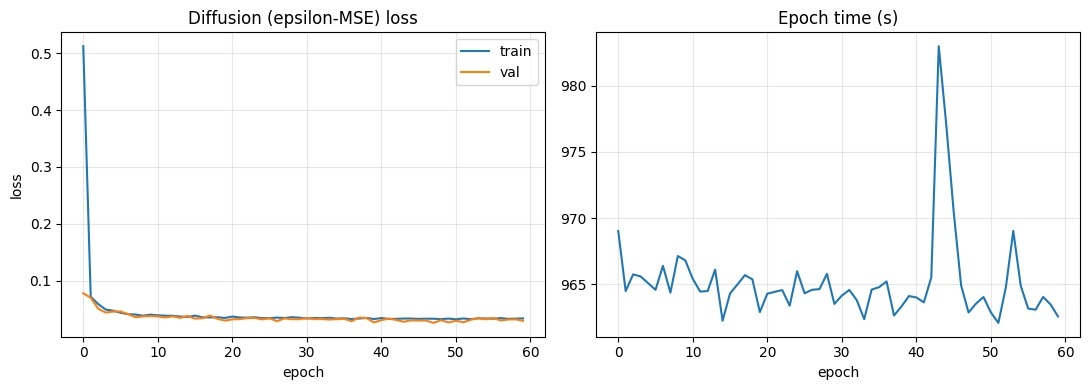

Saved loss curve + history -> outputs/loss_curve.png


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history["train_loss"], label="train")
ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("Diffusion (epsilon-MSE) loss"); ax[0].set_xlabel("epoch")
ax[0].set_ylabel("loss"); ax[0].legend(); ax[0].grid(True, alpha=0.3)
ax[1].plot(history["epoch_time_s"]); ax[1].set_title("Epoch time (s)")
ax[1].set_xlabel("epoch"); ax[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "loss_curve.png"), dpi=120); plt.show()

hist_path = os.path.join(OUTPUT_DIR, "training_history.json")
with open(hist_path, "w") as f:
    json.dump({"history": history, "best_val_loss": best_val,
               "config": dict(IMG_SIZE=IMG_SIZE, BASE_CHANNELS=BASE_CHANNELS,
                              COND_DIM=COND_DIM, CLIP_TEXT_DIM=CLIP_TEXT_DIM,
                              N_TIMESTEPS=N_TIMESTEPS, BETA_SCHEDULE=BETA_SCHEDULE,
                              TEXT_DROPOUT_PROB=TEXT_DROPOUT_PROB, EPOCHS=EPOCHS,
                              BATCH_SIZE=BATCH_SIZE)}, f, indent=2)
print(f"Saved loss curve + history -> {os.path.join(OUTPUT_DIR, 'loss_curve.png')}")


In [12]:
checkpoint = {
    "ema_state":   ema.state_dict(),
    "model_state": model.state_dict(),
    "config": {
        "IMG_SIZE": IMG_SIZE, "BASE_CHANNELS": BASE_CHANNELS, "COND_DIM": COND_DIM,
        "CLIP_TEXT_DIM": CLIP_TEXT_DIM, "N_TIMESTEPS": N_TIMESTEPS,
        "BETA_SCHEDULE": BETA_SCHEDULE, "IN_CHANNELS": IN_CHANNELS,
    },
    "best_val_loss": best_val,
    "history": history,
}
ckpt_path = os.path.join(OUTPUT_DIR, "ddpm_text_conditional.pt")
torch.save(checkpoint, ckpt_path)
print(f"Saved checkpoint -> {ckpt_path}")


Saved checkpoint -> outputs/ddpm_text_conditional.pt


## Task 4 — Integration Architecture (text → embedding → conditioning → image)

The reviewer-facing trace of how a prompt becomes an image in this pipeline:

1. **Text** — a natural-language caption (e.g. *"a child in a pink dress climbing stairs"*).
2. **Embedding** — the caption is tokenised by the CLIP ViT-B/32 text transformer and
   projected to a normalised **512-dim** vector `e_text`. A learnable **null token**
   `e_null` (initialised near zero) serves as the "no-text" embedding for CFG.
3. **Conditioning** — `e_text` (or `e_null`) is mapped by a small MLP into the U-Net's
   conditioning space and added to the sinusoidal **timestep** embedding, forming a single
   conditioning vector `c = emb(t) + emb_text`. `c` modulates every residual block's
   GroupNorm via **adaptive normalisation** (scale + shift), so the denoiser's behaviour is
   a function of both the noise level and the prompt.
4. **Image** — starting from Gaussian noise, the DDIM sampler calls the U-Net twice per
   step (conditional + unconditional) and applies **classifier-free guidance**
   `eps = eps_uncond + s·(eps_cond − eps_uncond)` to steer the denoised estimate toward
   the prompt, iterating to produce a 32×32 RGB image.

| Component | Choice |
|---|---|
| Text encoder | CLIP ViT-B/32 (frozen, 512-dim text features) |
| Conditioner | AdaGN (timestep + text embedding vector) |
| Generator | Text-conditional U-Net (eps-prediction; see param print above) |
| Diffusion | T=1000, cosine beta schedule |
| Guidance | Classifier-free, null token, `TEXT_DROPOUT_PROB=0.15` in training |
| Resolution | 64x64 (compute-budget choice; see summary) |


In [13]:
import imageio.v2 as imageio
import glob, re

files = sorted(glob.glob(os.path.join(GALLERY_DIR, "train_progress_epoch*.png")),
               key=lambda f: int(re.search(r"epoch(\d+)", f).group(1)))
frames = [imageio.imread(f) for f in files]
imageio.mimsave(os.path.join(GALLERY_DIR, "training_progress.gif"), frames, fps=2)
print(f"Saved GIF with {len(frames)} frames -> {GALLERY_DIR}/training_progress.gif")

Saved GIF with 60 frames -> gallery/training_progress.gif


In [14]:
# ---- Summary & rationale for the 64x64 choice ----
print("=" * 60)
print("MILESTONE 2 — INTEGRATION SUMMARY")
print("=" * 60)
print(f"Text encoder:        CLIP {CLIP_MODEL_NAME} (frozen)")
print(f"Generator:           TextConditionedUNet ({n_params/1e6:.2f}M params)")
print(f"Resolution:          {IMG_SIZE}x{IMG_SIZE}")
print(f"Diffusion:           T={N_TIMESTEPS}, {BETA_SCHEDULE} schedule, eps-prediction")
print(f"Guidance:            classifier-free, text dropout={TEXT_DROPOUT_PROB}")
print(f"Train/Val:           {len(df_train)} / {len(df_val)} pairs")
print(f"Best val loss:       {best_val:.5f}")
print(f"Epochs:              {EPOCHS}  (batch size {BATCH_SIZE})")
print(f"Steps/epoch:         {len(df_train) // BATCH_SIZE}")
print(f"Total steps:         {EPOCHS * (len(df_train) // BATCH_SIZE):,}")
total_s  = sum(history["epoch_time_s"])
avg_ep_s = total_s / len(history["epoch_time_s"])
print(f"Total training time: {total_s:.0f}s  ({total_s/3600:.1f} hrs)")
print(f"Avg epoch time:      {avg_ep_s:.1f}s")
print("-" * 60)
print("WHY 64x64: a from-scratch U-Net at this resolution trains in hours on a single")
print("consumer GPU and fits the compute budget, while still exposing the full")
print("text->embedding->conditioning->image conditioning pathway. Higher resolutions are")
print("left for the pretrained-SD track in a later milestone.")
print("=" * 60)


MILESTONE 2 — INTEGRATION SUMMARY
Text encoder:        CLIP openai/clip-vit-base-patch32 (frozen)
Generator:           TextConditionedUNet (75.42M params)
Resolution:          256x256
Diffusion:           T=1000, cosine schedule, eps-prediction
Guidance:            classifier-free, text dropout=0.15
Train/Val:           4500 / 500 pairs
Best val loss:       0.02606
Epochs:              60  (batch size 32)
Steps/epoch:         140
Total steps:         8,400
Total training time: 57910s  (16.1 hrs)
Avg epoch time:      965.2s
------------------------------------------------------------
WHY 64x64: a from-scratch U-Net at this resolution trains in hours on a single
consumer GPU and fits the compute budget, while still exposing the full
text->embedding->conditioning->image conditioning pathway. Higher resolutions are
left for the pretrained-SD track in a later milestone.


In [15]:
del model, ema, optimizer, scheduler, diffusion
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print("Milestone 2 — Integration & Training notebook complete.")
print("Next: run Milestone_2/Conditional_Generation.ipynb for generation + parameter sweeps.")


Milestone 2 — Integration & Training notebook complete.
Next: run Milestone_2/Conditional_Generation.ipynb for generation + parameter sweeps.
